
# Notebook 10: Feature Selection

## Objective
Learn how to identify and select useful features for machine learning
while reducing irrelevant, redundant, or unnecessary inputs.

## Learning Outcomes
- Understand feature selection and its benefits.
- Identify relevant, irrelevant, and redundant features.
- Apply correlation-based selection and variance threshold.
- Use univariate feature selection and mutual information.
- Apply Recursive Feature Elimination (RFE).
- Evaluate feature importance.
- Understand how unnecessary features affect model performance.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_selection import (
    VarianceThreshold,
    SelectKBest,
    f_regression,
    mutual_info_regression
)
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score, mean_absolute_error

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
np.random.seed(42)

n = 300

area = np.random.randint(500, 3000, n)
bedrooms = np.random.randint(1, 6, n)
age = np.random.randint(0, 40, n)
location_score = np.random.uniform(1, 10, n)

df_features = pd.DataFrame({
    "Area": area,
    "Bedrooms": bedrooms,
    "Age": age,
    "Location_Score": location_score,
    "Area_Copy": area * 2,
    "Constant_Feature": 1,
    "Random_Noise": np.random.normal(0, 1, n),
    "Property_ID": range(1001, 1001 + n)
})

df_features["Price"] = (
    1500 * df_features["Area"]
    + 150000 * df_features["Bedrooms"]
    - 10000 * df_features["Age"]
    + 50000 * df_features["Location_Score"]
    + np.random.normal(0, 100000, n)
)

print("Dataset shape:", df_features.shape)
display(df_features.head())

Dataset shape: (300, 9)


,Area,Bedrooms,Age,Location_Score,Area_Copy,Constant_Feature,Random_Noise,Property_ID,Price
0,1360,5,17,4.139814,2720,1,0.429618,1001,2.819831e+06
1,1794,5,13,9.365762,3588,1,0.207688,1002,3.775566e+06
2,1630,1,14,8.475575,3260,1,0.271579,1003,2.951542e+06
3,1595,3,30,9.685242,3190,1,-1.276749,1004,3.031957e+06
4,2138,2,0,2.118675,4276,1,-1.081057,1005,3.686198e+06



## 1. What Is Feature Selection?

Feature selection is the process of choosing the most useful input
features for a machine learning model.

### Why feature selection?
- Reduce unnecessary input variables.
- Simplify models and improve interpretability.
- Reduce computation and training time.
- Reduce overfitting risk in some situations.
- Remove redundant or uninformative features.

### Types of features

**Relevant features:** Contain useful information about the target.

**Irrelevant features:** Provide little or no useful predictive information.

**Redundant features:** Repeat information already represented by
other features.

Feature selection should be performed using training data and
validated on data that was not used to select the features.


In [3]:
X = df_features.drop(columns=["Price"])
y = df_features["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

Training features: (240, 8)
Testing features: (60, 8)



## 2. Relevant, Irrelevant, and Redundant Features

- Area is relevant because larger properties generally cost more.
- Bedrooms can be relevant to property prices.
- Age can be relevant because property condition and depreciation
  may influence prices.
- Area_Copy duplicates the information in Area.
- Constant_Feature has no variation.
- Random_Noise is designed to contain no meaningful price signal.
- Property_ID is an identifier and should not automatically be
  treated as a useful predictive feature.

A feature's usefulness depends on the real dataset and prediction
task. These examples illustrate common patterns.


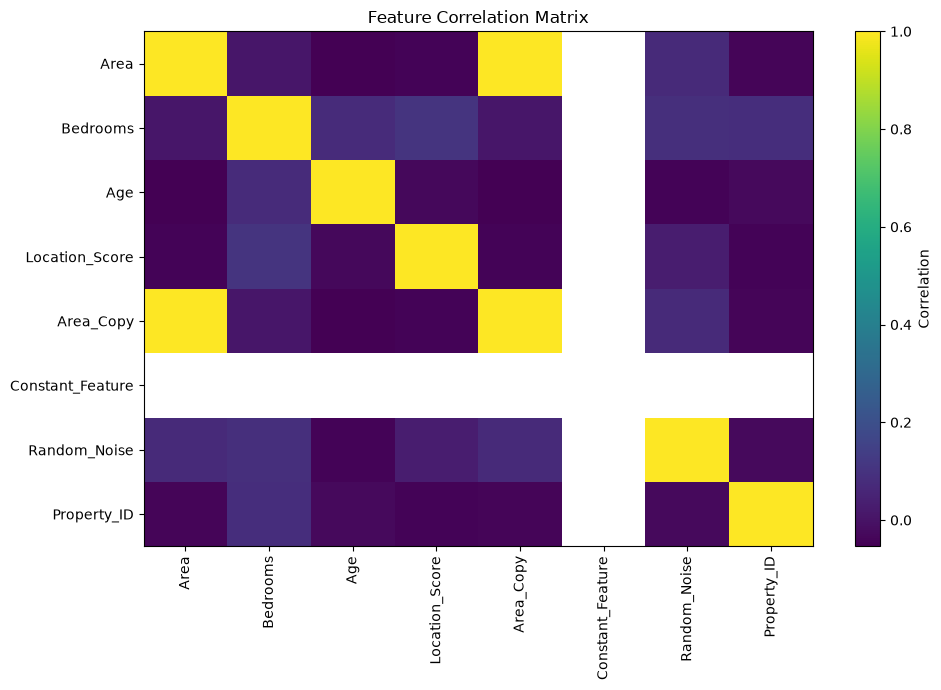

In [4]:
correlation = X_train.corr(numeric_only=True)

plt.figure(figsize=(10, 7))
plt.imshow(correlation, aspect="auto")
plt.colorbar(label="Correlation")
plt.xticks(
    range(len(correlation.columns)),
    correlation.columns,
    rotation=90
)
plt.yticks(range(len(correlation.columns)), correlation.columns)
plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()

In [5]:
train_corr = X_train.copy()
train_corr["Price"] = y_train

target_correlation = (
    train_corr.corr(numeric_only=True)["Price"]
    .drop("Price")
    .sort_values(key=abs, ascending=False)
)

display(target_correlation.to_frame("Correlation_with_Price"))

,Correlation_with_Price
Area,0.960541
Area_Copy,0.960541
Bedrooms,0.214800
Age,-0.146329
Location_Score,0.100124
Random_Noise,0.088549
Property_ID,-0.031877
Constant_Feature,NaN


In [6]:
variance_selector = VarianceThreshold(threshold=0)

variance_selector.fit(X_train)

selected_variance_features = X_train.columns[
    variance_selector.get_support()
].tolist()

removed_variance_features = X_train.columns[
    ~variance_selector.get_support()
].tolist()

print("Features retained:")
print(selected_variance_features)

print("\nFeatures removed:")
print(removed_variance_features)

Features retained:
['Area', 'Bedrooms', 'Age', 'Location_Score', 'Area_Copy', 'Random_Noise', 'Property_ID']

Features removed:
['Constant_Feature']


In [7]:
# Exclude identifiers and constant columns for this demonstration.
excluded = ["Property_ID", "Constant_Feature"]

X_train_uni = X_train.drop(columns=excluded)

univariate_selector = SelectKBest(
    score_func=f_regression,
    k=4
)

univariate_selector.fit(X_train_uni, y_train)

univariate_scores = pd.DataFrame({
    "Feature": X_train_uni.columns,
    "F_Score": univariate_selector.scores_,
    "Selected": univariate_selector.get_support()
}).sort_values("F_Score", ascending=False)

display(univariate_scores)

,Feature,F_Score,Selected
0,Area,2838.505830,True
4,Area_Copy,2838.505830,True
1,Bedrooms,11.512305,True
2,Age,5.207568,True
3,Location_Score,2.410052,False
5,Random_Noise,1.880903,False


In [8]:
mi_scores = mutual_info_regression(
    X_train_uni,
    y_train,
    random_state=42
)

mi_results = pd.DataFrame({
    "Feature": X_train_uni.columns,
    "Mutual_Information": mi_scores
}).sort_values("Mutual_Information", ascending=False)

display(mi_results)

,Feature,Mutual_Information
0,Area,1.237924
4,Area_Copy,1.236904
1,Bedrooms,0.057068
3,Location_Score,0.034804
2,Age,0.019650
5,Random_Noise,0.000000


In [9]:
# Use numerical features and exclude the ID and constant column.
X_train_rfe = X_train_uni.copy()

rfe_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

rfe = RFE(
    estimator=rfe_model,
    n_features_to_select=4
)

rfe.fit(X_train_rfe, y_train)

rfe_results = pd.DataFrame({
    "Feature": X_train_rfe.columns,
    "Selected": rfe.support_,
    "Ranking": rfe.ranking_
}).sort_values("Ranking")

display(rfe_results)

,Feature,Selected,Ranking
0,Area,True,1
1,Bedrooms,True,1
3,Location_Score,True,1
4,Area_Copy,True,1
2,Age,False,2
5,Random_Noise,False,3


,Feature,Importance
4,Area_Copy,0.474867
0,Area,0.467969
1,Bedrooms,0.024087
3,Location_Score,0.018610
2,Age,0.008740
5,Random_Noise,0.005728


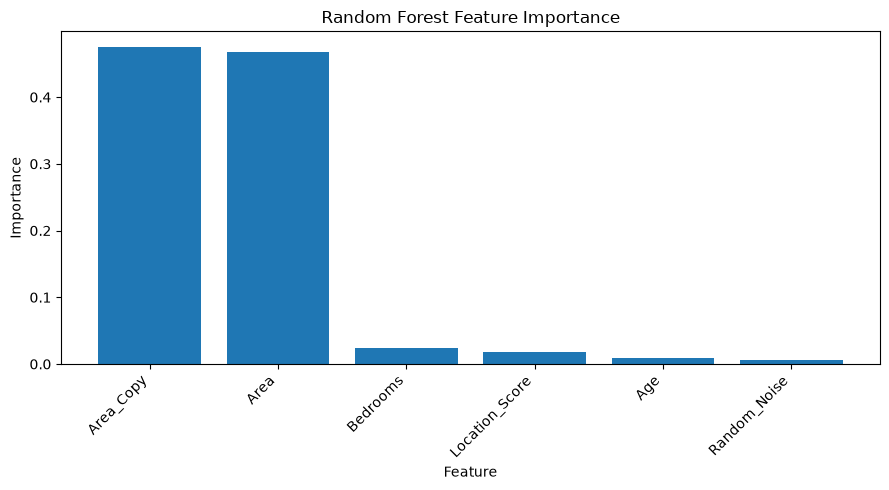

In [10]:
importance_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

importance_model.fit(X_train_uni, y_train)

importance_results = pd.DataFrame({
    "Feature": X_train_uni.columns,
    "Importance": importance_model.feature_importances_
}).sort_values("Importance", ascending=False)

display(importance_results)

plt.figure(figsize=(9, 5))
plt.bar(
    importance_results["Feature"],
    importance_results["Importance"]
)
plt.title("Random Forest Feature Importance")
plt.xlabel("Feature")
plt.ylabel("Importance")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [11]:
# Baseline model: use all original features.
baseline_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

baseline_model.fit(X_train, y_train)
baseline_predictions = baseline_model.predict(X_test)

# Reduced model: exclude ID, constant, redundant copy, and noise.
reduced_columns = [
    "Area", "Bedrooms", "Age", "Location_Score"
]

reduced_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

reduced_model.fit(X_train[reduced_columns], y_train)
reduced_predictions = reduced_model.predict(X_test[reduced_columns])

comparison = pd.DataFrame({
    "Model": ["All features", "Reduced features"],
    "Test_MAE": [
        mean_absolute_error(y_test, baseline_predictions),
        mean_absolute_error(y_test, reduced_predictions)
    ],
    "Test_R2": [
        r2_score(y_test, baseline_predictions),
        r2_score(y_test, reduced_predictions)
    ]
})

display(comparison)

,Model,Test_MAE,Test_R2
0,All features,168183.221114,0.963274
1,Reduced features,152809.243560,0.968102



## 3. Effects of Unnecessary Features

Unnecessary features can:
- Increase training and inference time.
- Increase memory usage.
- Add noise that makes patterns harder to learn.
- Increase overfitting risk for some algorithms.
- Make models more difficult to interpret.
- Create multicollinearity when features are redundant.
- Increase the cost of collecting and maintaining data.

However, a feature should not be removed only because it seems
unimportant in isolation. It may contain useful information through
interactions with other features.

Feature selection should be justified by domain knowledge,
training data analysis, and validation results.



## Conclusion

In this notebook, I learned the purpose of feature selection and
the differences between relevant, irrelevant, and redundant features.

I applied correlation-based analysis, variance threshold,
univariate feature selection, mutual information, Recursive Feature
Elimination, and model-based feature importance.

I also compared model performance using all features and a reduced
feature set.

Feature selection can reduce complexity, computation, and noise,
but it must be validated carefully to avoid removing useful information
or introducing data leakage.
